In [3]:
%cd ..

/home/willraftery/PhD/projects/github/emg-stream


In [ ]:
from pathlib import Path

dataset_dir = Path("data/uci_emg")

with h5py.File(output_fpath, "w") as f:
    root = f.create_group("epn612")

    user_dirs = list(dataset_dir.iterdir())
    participant_num = 0
    for user_dir in user_dirs:
        if not user_dir.is_dir(): continue

        participant_num += 1



User: 03
  - 2_raw_data_09-34_11.04.16.txt
  - 1_raw_data_09-32_11.04.16.txt
User: 16
  - 1_raw_data_12-12_25.04.16.txt
  - 2_raw_data_12-14_25.04.16.txt
User: 35
  - 1_raw_data_10-03_13.04.16.txt
  - 2_raw_data_10-05_13.04.16.txt
User: 22
  - 2_raw_data_12-39_28.03.16.txt
  - 1_raw_data_12-37_28.03.16.txt
User: 17
  - 2_raw_data_11-20_23.03.16.txt
  - 1_raw_data_11-19_23.03.16.txt
User: 36
  - 1_raw_data_13-03_15.04.16.txt
  - 2_raw_data_13-04_15.04.16.txt
User: 30
  - 1_raw_data_09-49_21.03.16.txt
  - 2_raw_data_09-50_21.03.16.txt
User: 14
  - 1_raw_data_09-50_15.04.16.txt
  - 2_raw_data_09-51_15.04.16.txt
User: 20
  - 1_raw_data_11-41_22.03.16.txt
  - 2_raw_data_11-43_22.03.16.txt
User: 11
  - 1_raw_data_13-11_18.03.16.txt
  - 2_raw_data_13-13_18.03.16.txt
User: README.txt


NotADirectoryError: [Errno 20] Not a directory: 'data/uci_emg/README.txt'

(13128, 8)
(13128,)
(13128,)
[0.006 0.011 0.016 0.021 0.026 0.031 0.036 0.041 0.046 0.051]


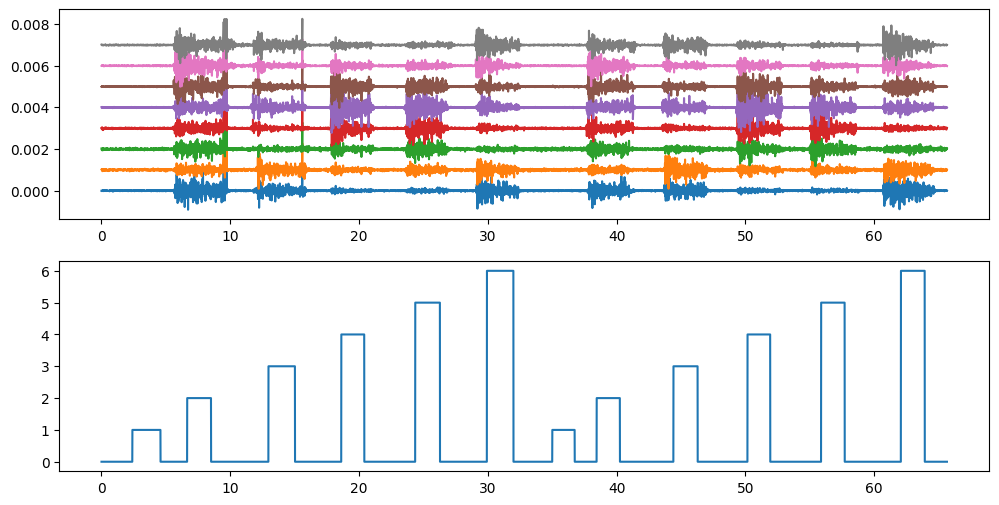

(12127, 8)
(12127,)
(12127,)
[0.008 0.013 0.018 0.023 0.028 0.033 0.038 0.043 0.048 0.053]


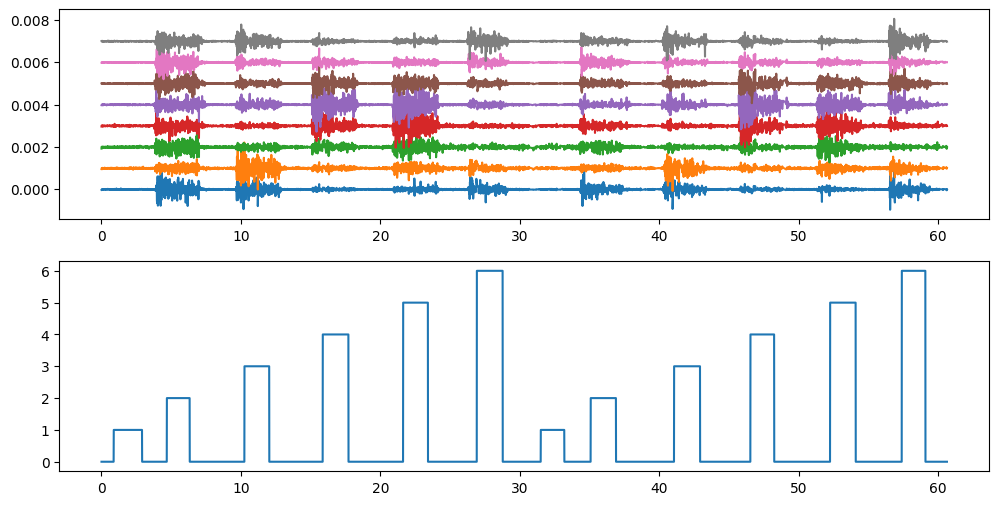

(14121, 8)
(14121,)
(14121,)
[0.016 0.021 0.026 0.031 0.036 0.041 0.046 0.051 0.056 0.061]


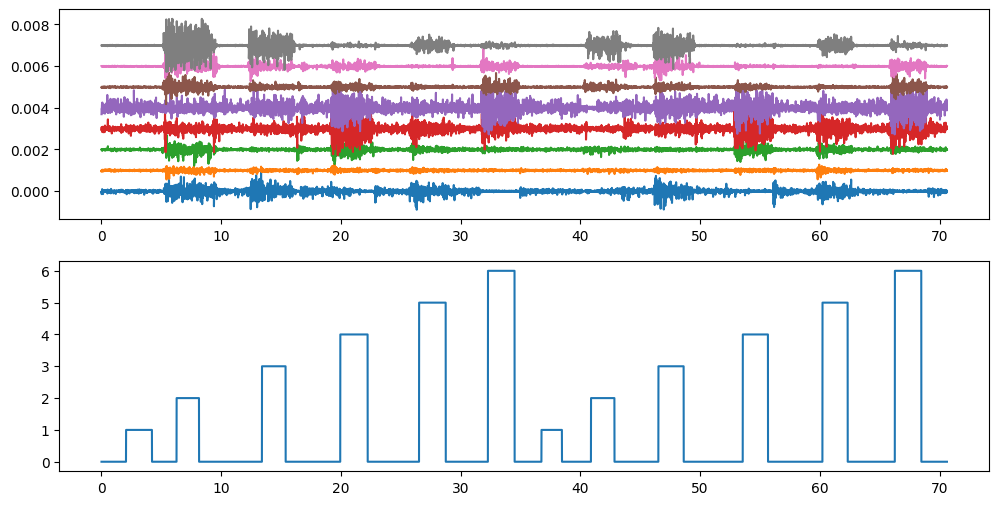

(13154, 8)
(13154,)
(13154,)
[0.009 0.014 0.019 0.024 0.029 0.034 0.039 0.044 0.049 0.054]


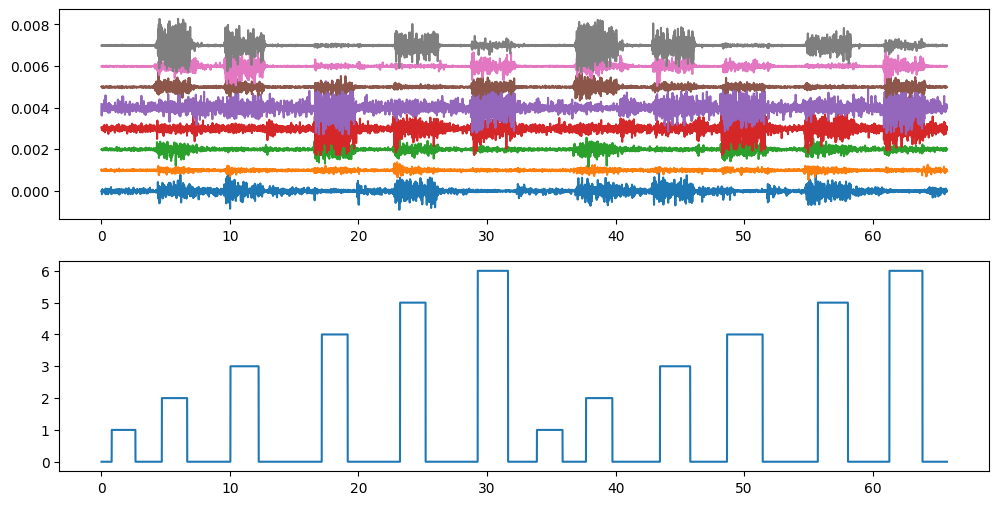

(15413, 8)
(15413,)
(15413,)
[0.022 0.027 0.032 0.037 0.042 0.047 0.052 0.057 0.062 0.067]


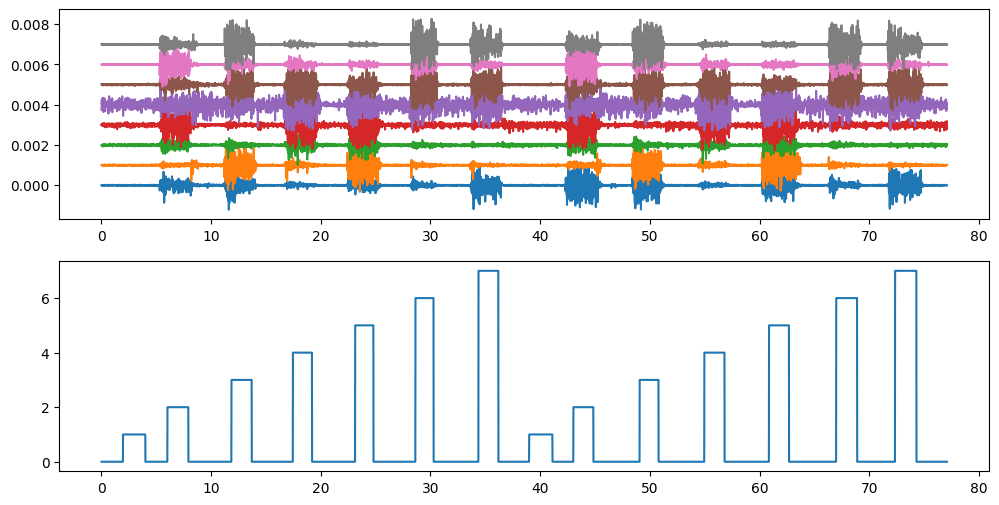

(15052, 8)
(15052,)
(15052,)
[0.004 0.009 0.014 0.019 0.024 0.029 0.034 0.039 0.044 0.049]


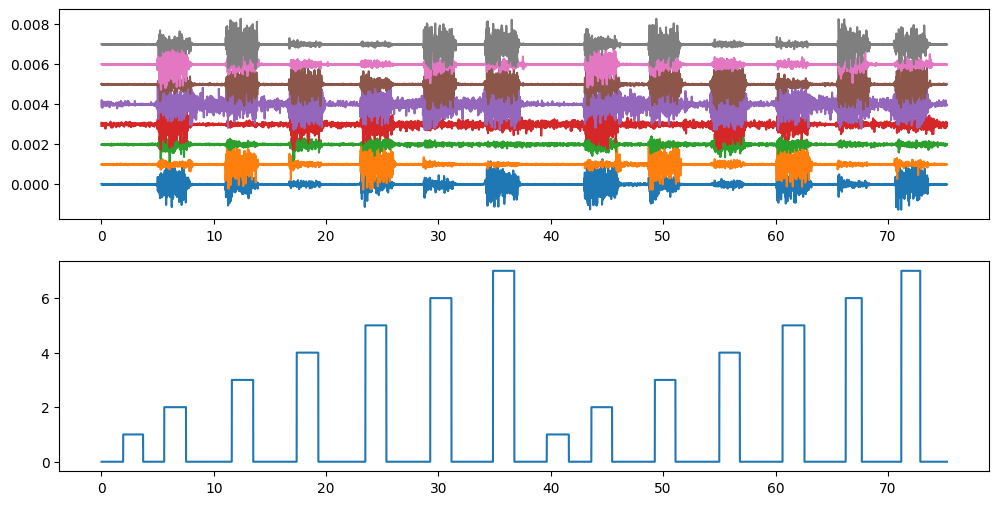

In [33]:
import pandas as pd
import numpy as np
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

def load_and_clean_uci_emg(file_path, target_fs=200):
    # 1. Load the raw text file
    # The files are space/tab separated with a header row
    df = pd.read_csv(file_path, sep='\t')
    
    # 2. De-duplicate: Remove rows where EMG values are identical to previous row
    # We keep the first occurrence. This removes the 'staircase' effect.
    emg_cols = [c for c in df.columns if 'channel' in c.lower()]

    # emg_data = df[emg_cols].to_numpy()
    # print(emg_data.shape)

    # emg_plot_data = emg_data[10000:11000]
    # emg_plot_data /= np.max(np.abs(emg_plot_data))  # Normalize for better visualization

    # plt.figure(figsize=(12, 6))
    # offset = np.arange(emg_plot_data.shape[1]) * 0.5  # Offset each channel for visibility
    # plt.plot(emg_plot_data + offset[None, :])



    unique_mask = df[emg_cols].diff().abs().sum(axis=1) != 0
    df_unique = df[unique_mask].copy()
    
    # 3. Handle Timestamps
    # Convert 'time' column to seconds for the interpolator
    times = df_unique['time'].values / 1000.0 
    data = df_unique[emg_cols].values
    labels = df_unique['class'].values
    
    # 4. Create Uniform Time Grid
    # We want a sample every 1/target_fs seconds (e.g., every 0.005s)
    t_start = times[0]
    t_end = times[-1]
    t_uniform = np.arange(t_start, t_end, 1/target_fs)
    
    # 5. Interpolate EMG Signals
    # We use linear interpolation to estimate values at the exact 5ms marks
    f_emg = interp1d(times, data, axis=0, kind='linear', fill_value="extrapolate")
    emg_uniform = f_emg(t_uniform)
    
    # 6. Interpolate Labels (Nearest Neighbor)
    # Labels shouldn't be averaged; we take the label of the closest original timestamp
    f_label = interp1d(times, labels, kind='nearest', fill_value="extrapolate")
    labels_uniform = f_label(t_uniform)
    
    return t_uniform, emg_uniform, labels_uniform

# --- Visualization Script ---
file_path = "data/uci_emg/01/1_raw_data_13-12_22.03.16.txt"
t, emg, labels = load_and_clean_uci_emg(file_path)
print(emg.shape)
print(labels.shape)
print(t.shape)
print(t[:10])

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)

emg_plot = emg  # Plot only the first 10,000 samples for clarity
t_plot = t
offset = np.arange(emg.shape[1]) * 0.001  # Offset each channel for visibility
plt.plot(t_plot, emg_plot + offset[None, :])

plt.subplot(2, 1, 2)

label_plot = labels # Plot only the first 10,000 samples for clarity
plt.plot(t_plot, label_plot)
# plt.tight_layout()

plt.show()


# --- Visualization Script ---
file_path = "data/uci_emg/01/2_raw_data_13-13_22.03.16.txt"
t, emg, labels = load_and_clean_uci_emg(file_path)
print(emg.shape)
print(labels.shape)
print(t.shape)
print(t[:10])

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)

emg_plot = emg  # Plot only the first 10,000 samples for clarity
t_plot = t
offset = np.arange(emg.shape[1]) * 0.001  # Offset each channel for visibility
plt.plot(t_plot, emg_plot + offset[None, :])

plt.subplot(2, 1, 2)

label_plot = labels # Plot only the first 10,000 samples for clarity
plt.plot(t_plot, label_plot)
# plt.tight_layout()

plt.show()



# --- Visualization Script ---
file_path = "data/uci_emg/07/1_raw_data_18-48_22.03.16.txt"
t, emg, labels = load_and_clean_uci_emg(file_path)
print(emg.shape)
print(labels.shape)
print(t.shape)
print(t[:10])

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)

emg_plot = emg  # Plot only the first 10,000 samples for clarity
t_plot = t
offset = np.arange(emg.shape[1]) * 0.001  # Offset each channel for visibility
plt.plot(t_plot, emg_plot + offset[None, :])

plt.subplot(2, 1, 2)

label_plot = labels # Plot only the first 10,000 samples for clarity
plt.plot(t_plot, label_plot)
# plt.tight_layout()

plt.show()


# --- Visualization Script ---
file_path = "data/uci_emg/07/2_raw_data_18-50_22.03.16.txt"
t, emg, labels = load_and_clean_uci_emg(file_path)
print(emg.shape)
print(labels.shape)
print(t.shape)
print(t[:10])

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)

emg_plot = emg  # Plot only the first 10,000 samples for clarity
t_plot = t
offset = np.arange(emg.shape[1]) * 0.001  # Offset each channel for visibility
plt.plot(t_plot, emg_plot + offset[None, :])

plt.subplot(2, 1, 2)

label_plot = labels # Plot only the first 10,000 samples for clarity
plt.plot(t_plot, label_plot)
# plt.tight_layout()

plt.show()


file_path = "data/uci_emg/11/1_raw_data_13-11_18.03.16.txt"
t, emg, labels = load_and_clean_uci_emg(file_path)
print(emg.shape)
print(labels.shape)
print(t.shape)
print(t[:10])

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)

emg_plot = emg  # Plot only the first 10,000 samples for clarity
t_plot = t
offset = np.arange(emg.shape[1]) * 0.001  # Offset each channel for visibility
plt.plot(t_plot, emg_plot + offset[None, :])

plt.subplot(2, 1, 2)

label_plot = labels # Plot only the first 10,000 samples for clarity
plt.plot(t_plot, label_plot)
# plt.tight_layout()

plt.show()

file_path = "data/uci_emg/11/2_raw_data_13-13_18.03.16.txt"
t, emg, labels = load_and_clean_uci_emg(file_path)
print(emg.shape)
print(labels.shape)
print(t.shape)
print(t[:10])

plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)

emg_plot = emg  # Plot only the first 10,000 samples for clarity
t_plot = t
offset = np.arange(emg.shape[1]) * 0.001  # Offset each channel for visibility
plt.plot(t_plot, emg_plot + offset[None, :])

plt.subplot(2, 1, 2)

label_plot = labels # Plot only the first 10,000 samples for clarity
plt.plot(t_plot, label_plot)
# plt.tight_layout()

plt.show()

# # Plot only the first 2 seconds for clarity
# mask = t < (t[0] + 2.0)

# plt.subplot(2, 1, 1)
# plt.plot(t[mask], emg[mask])
# plt.title("Jitter-Corrected EMG (Uniform 200Hz)")
# plt.ylabel("Normalized Amplitude")

# plt.subplot(2, 1, 2)
# plt.plot(t[mask], labels[mask], color='red', drawstyle='steps-post')
# plt.title("Gesture Labels")
# plt.xlabel("Time (s)")
# plt.ylabel("Class ID")

# plt.tight_layout()
# plt.show()

In [29]:
print(type(emg))
print(type(labels))
print(type(t))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [4]:
import h5py
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
import re

def extract_dataset_metadata(hdf5_path, root_key):
    """
    Crawls a unified biosignal HDF5 file and flattens metadata into a DataFrame.
    """
    records = []
    with h5py.File(hdf5_path, 'r') as f:
        if root_key not in f:
            raise KeyError(f"Root key '{root_key}' not found in {hdf5_path}")
        
        root = f[root_key]
        for subj_id in tqdm(root.keys(), desc=f"Scanning {root_key}"):
            subj_group = root[subj_id]
            subj_meta = dict(subj_group.attrs)
            
            for sess_id in subj_group.keys():
                if not isinstance(subj_group[sess_id], h5py.Group):
                    continue
                
                sess_group = subj_group[sess_id]
                sess_meta = dict(sess_group.attrs)

                for run_key in sess_group.keys():
                    if not isinstance(sess_group[run_key], h5py.Group):
                        continue
                    
                    run_group = sess_group[run_key]
                    run_meta = dict(run_group.attrs)
                
                    # Signal metrics
                    emg_data = run_group['emg']
                    t, c = emg_data.shape
                    fs = run_group['emg'].attrs['sample_rate']
                    # fs = sess_meta.get('sample_rate', 200)
                    
                    # Combine metadata
                    record = {
                        **subj_meta,
                        **sess_meta,
                        **run_meta,
                        'subj_key': subj_id,
                        'sess_key': sess_id,
                        'run_key': run_key,
                        'num_samples': t,
                        'num_channels': c,
                        'duration_sec': t / fs,
                        'emg_mean': np.mean(emg_data),
                        'emg_std': np.std(emg_data)
                    }
                    records.append(record)
                
    df = pd.DataFrame(records)
    # Ensure participant_num is a sortable type (int if possible)
    # Participarn ID is often a string like "subject_01", so we can extract the numeric part for sorting
    try:
        regex = re.compile(r'\d+')
        df['participant_number'] = df['participant_id'].apply(lambda x: int(regex.search(str(x)).group()) if regex.search(str(x)) else x)
        df.sort_values('participant_number', inplace=True)
    except:
        pass
        
    return df

In [39]:
df = extract_dataset_metadata("data/uci_emg/uci_emg.hdf5", "uci_emg")

Scanning uci_emg: 100%|██████████| 36/36 [00:00<00:00, 92.96it/s]


In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import re

class BiosignalAuditor:
    def __init__(self, df, dataset_name="Dataset"):
        self.df = df
        self.df.sort_values('participant_number', inplace=True)
        self.name = dataset_name.upper()
        # Filter out unlabelled for core distribution plots
        self.df_clean = df[df['gesture_id'] != -1].copy()
        
        plt.style.use('seaborn-v0_8-muted')
        sns.set_context("talk")

    def run_full_audit(self):
        """Executes all visualization and statistical checks."""
        self.plot_overview()
        self.plot_length_leakage_check()
        self.print_summary()


    def plot_overview(self):
        fig, axes = plt.subplots(4, 2, figsize=(20, 30))
        plt.subplots_adjust(hspace=0.4)
            
        # 1. Class Distribution (Gesture ID)
        # This checks for "Label Imbalance"
        sns.countplot(data=self.df, x='gesture_id', hue='intra_session_split', ax=axes[0,0])
        axes[0,0].set_title("Gesture Class Distribution (Intra-Session Split)")
        axes[0,0].tick_params(axis='x', rotation=45)


        sns.countplot(data=self.df, x='gesture_id', hue='inter_subject_split', ax=axes[0,1])
        axes[0,1].set_title("Gesture Class Distribution (Inter-Subject Split)")
        axes[0,1].tick_params(axis='x', rotation=45)


        # 2. Duration Distribution
        sns.histplot(data=self.df_clean, x='duration_sec', hue='intra_session_split', multiple="stack", ax=axes[1,0])
        axes[1,0].set_title("Distribution of Trial Durations - Intra-session split (Seconds)")

        sns.histplot(data=self.df_clean, x='duration_sec', hue='inter_subject_split', multiple="stack", ax=axes[1,1])
        axes[1,1].set_title("Distribution of Trial Durations - Inter-subject split (Seconds)")

        # 3. Leakage Heatmap (Subject-to-Split Mapping)
        leak_table = pd.crosstab(self.df_clean['participant_number'], self.df['intra_session_split'])
        sns.heatmap(leak_table, annot=False, cbar=False, cmap='Blues', ax=axes[2,0])
        axes[2,0].set_title("Session Leakage Check")

        leak_table = pd.crosstab(self.df_clean['participant_number'], self.df['inter_subject_split'])
        sns.heatmap(leak_table, annot=False, cbar=False, cmap='Blues', ax=axes[2,1])
        axes[2,1].set_title("Subject Leakage Check")

        # 4. Signal Quality (Mean vs Std per Subject)
        sns.scatterplot(data=self.df_clean, x='emg_mean', y='emg_std', hue='participant_id', alpha=0.5, ax=axes[3,1])
        axes[3,1].set_title("Signal Energy (Mean vs Std) - Quality Check")
        axes[3,1].get_legend().remove()

        plt.show()

    def plot_length_leakage_check(self):
        """Checks if gesture ID is perfectly predictable by signal duration."""
        plt.figure(figsize=(16, 6))
        sns.boxplot(data=self.df_clean.sort_values('gesture_id'), x='gesture_id', y='duration_sec', palette='husl')
        plt.axhline(self.df_clean['duration_sec'].mean(), color='red', linestyle='--', alpha=0.6, label='Global Mean')
        plt.title(f"{self.name}: Signal Length Leakage Audit")
        plt.xticks(rotation=90 if self.df_clean['gesture_id'].nunique() > 10 else 0)
        plt.legend()
        plt.show()

    def print_summary(self):
        print(f"\n{'='*40}\n{self.name} AUDIT REPORT\n{'='*40}")
        print(f"Total Subjects: {self.df['participant_id'].nunique()}")
        print(f"Total Trials:   {len(self.df)}")
        print(f"Total EMG Time: {self.df['duration_sec'].sum() / 3600:.2f} hours")
        
        for col in ['intra_session_split', 'intra_session_split', 'subject_split', 'inter_subject_split']:
            if col in self.df.columns:
                print(f"\nSplit Distribution ({col}):")
                print(self.df[col].value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

        # Check for Inter-Subject Leakage
        subj_split_col = next((c for c in ['subject_split', 'inter_subject_split'] if c in self.df.columns), None)
        if subj_split_col:
            leak_check = self.df.groupby('participant_id')[subj_split_col].nunique()
            leaked = leak_check[leak_check > 1].index.tolist()
            if leaked:
                print(f"\n⚠️ WARNING: {len(leaked)} subjects found in multiple splits: {leaked[:5]}...")
            else:
                print("\n✅ Clean: No subject leakage detected across splits.")

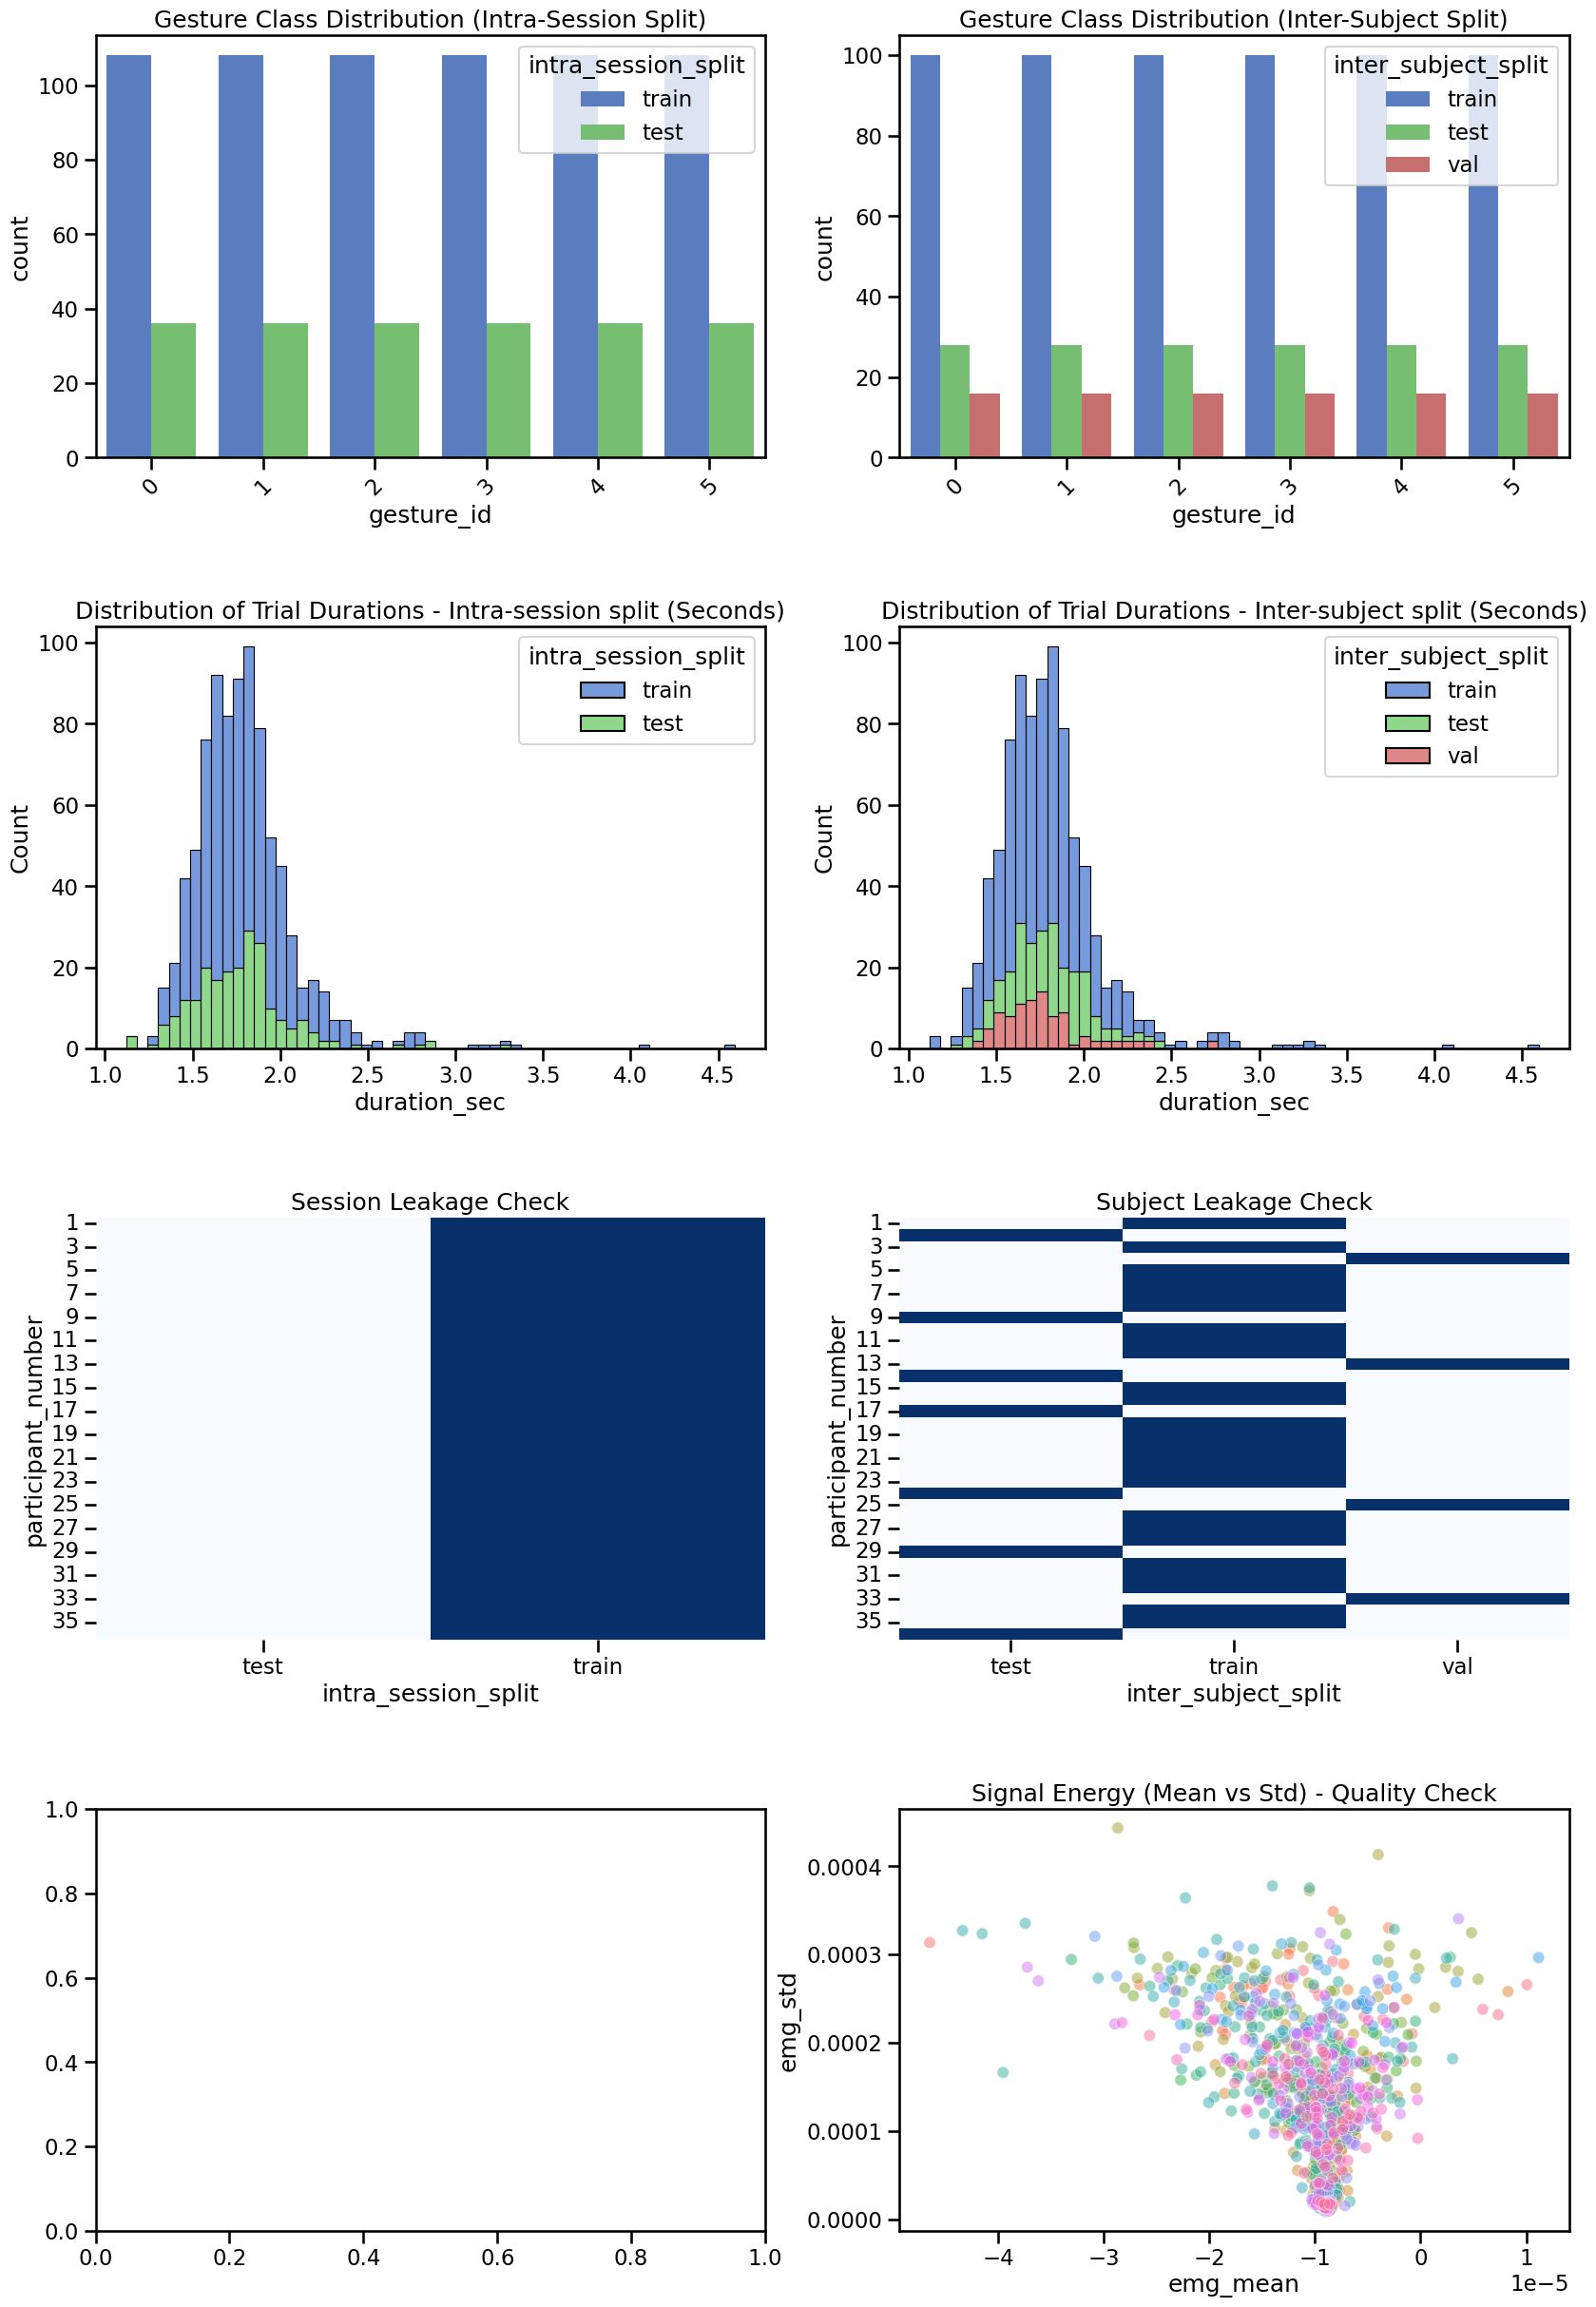

/tmp/ipykernel_3045109/1223819481.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=self.df_clean.sort_values('gesture_id'), x='gesture_id', y='duration_sec', palette='husl')


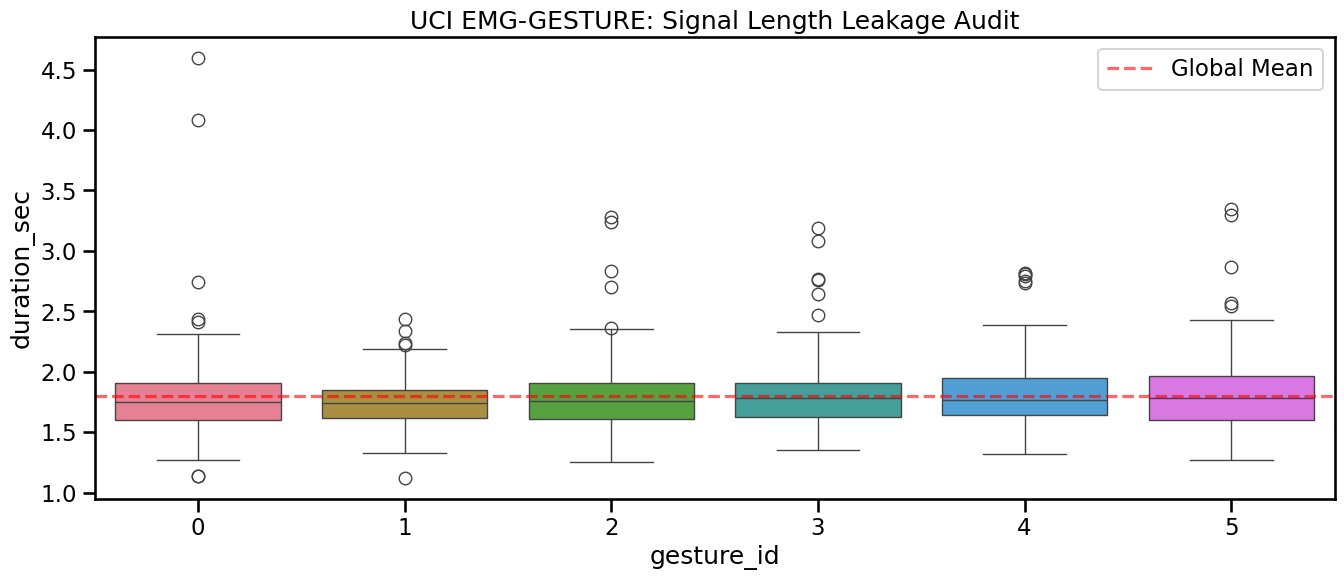

AttributeError: 'BiosignalAuditor' object has no attribute 'hdf5_path'

In [49]:
auditor = BiosignalAuditor(df, "UCI EMG-Gesture")
auditor.run_full_audit()

In [6]:
def plot_global_amplitude_histogram(hdf5_path, root_key, n_runs_to_sample=50):
    """
    Plots a histogram of all raw EMG datapoints across a subset of runs.
    This reveals the statistical distribution (PDF) of the signal.
    """
    all_values = []
    
    with h5py.File(hdf5_path, 'r') as f:
        for subj_id in f[root_key].keys():
            subj_group = f[root_key][subj_id]
            for sess_id in subj_group.keys():
                sess_group = subj_group[sess_id]
                for run_key in sess_group.keys():
                    run_group = sess_group[run_key]
                    emg_data = run_group['emg'][:]
                    all_values.extend(emg_data.flatten())
    
    all_values = np.array(all_values)

    plt.figure(figsize=(12, 6))
    
    # Using a log scale for the Y-axis is often better for EMG 
    # because the 'Rest' zeros dominate the count.
    sns.histplot(all_values, bins=100, kde=True, color='teal')
    
    plt.yscale('log') 
    plt.title(f"{root_key}: Global Amplitude Distribution (All Datapoints)")
    plt.xlabel("Amplitude (Normalized units)")
    plt.ylabel("Frequency (Log Scale)")
    plt.grid(True, which="both", ls="-", alpha=0.2)
    
    # Add vertical lines for standard deviations
    std = np.std(all_values)
    plt.axvline(std, color='orange', linestyle='--', label=f'1 Std ({std:.2f})')
    plt.axvline(-std, color='orange', linestyle='--')
    plt.legend()

    print(f"Min Amplitude: {all_values.min():.4f}, Max Amplitude: {all_values.max():.4f}, Mean: {all_values.mean():.4f}, Std: {std:.4f}")
    
    plt.show()

Min Amplitude: -0.9846, Max Amplitude: 0.9769, Mean: -0.0083, Std: 0.1365


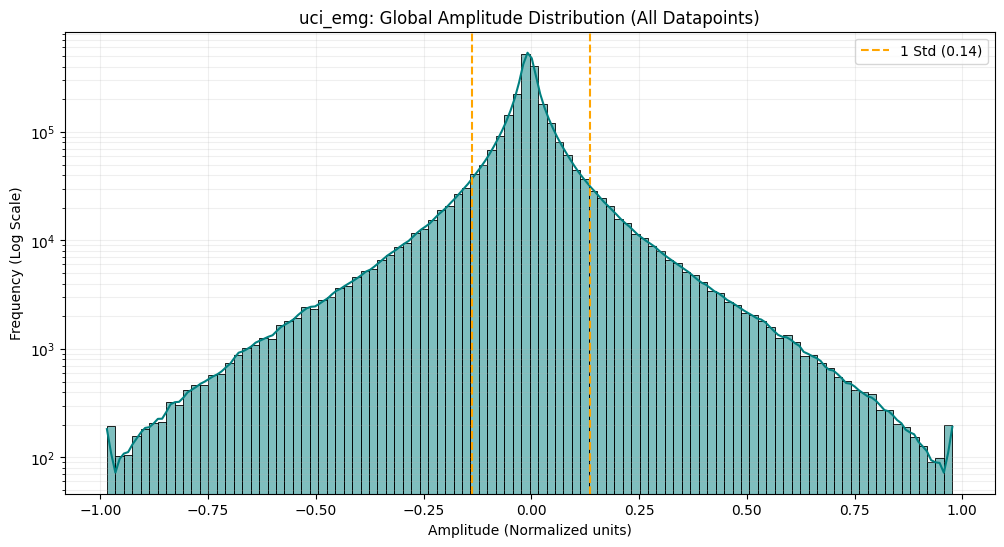

In [10]:
plot_global_amplitude_histogram("data/uci_emg/uci_emg.hdf5", "uci_emg", n_runs_to_sample=50)